# Imports

In [ ]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
import datasets
import numpy as np
import pandas as pd
import transformers
import sklearn.metrics
# import tensorflow as tf
import torch
import tqdm.notebook as tqdm
import sklearn.model_selection
import matplotlib.pyplot as plt

import itertools
import typing
from pathlib import Path
import collections

In [2]:
keras.__version__, keras.backend.backend()

('3.15.1', 'torch')

In [3]:
# gpus = tf.config.list_physical_devices('GPU')
# if gpus:
#     try:
#         tf.config.experimental.set_memory_growth(gpus[0], True)
#         print(gpus)
#     except:
#         print("No GPU")

gpus = [torch.cuda.device(i) for i in range(torch.cuda.device_count())]
if gpus:
    try:
        torch.cuda.set_per_process_memory_fraction(0.5)
        for i in range(torch.cuda.device_count()):
           print(torch.cuda.get_device_properties(i))
    except:
        print("No GPU")


_CudaDeviceProperties(name='NVIDIA GeForce RTX 3060', major=8, minor=6, total_memory=12287MB, multi_processor_count=28, uuid=9c6396a2-0e5e-4445-8ae5-e68074710ca5, pci_bus_id=1, pci_device_id=0, pci_domain_id=0, L2_cache_size=2MB)


# Dataset

Load the dataset (we will be using [go_emotions](https://huggingface.co/datasets/google-research-datasets/go_emotions)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset. Implement two datasets: variable and fixed sentence length (in tokens). Don't forget to split the dataset into train and test subsets

In [4]:
dataset = datasets.load_dataset('google-research-datasets/go_emotions', name='raw', split='train')

In [5]:
df_dataset = pd.DataFrame.from_dict(dataset)

In [6]:
emotions = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity',
    'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear',
    'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief',
    'remorse', 'sadness', 'surprise', 'neutral'
]

In [7]:
df_dataset.loc[:, emotions]

,admiration,amusement,anger,annoyance,approval,caring,confusion,curiosity,desire,disappointment,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211220,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
211221,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
211222,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
211223,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
y_main = df_dataset.loc[:, emotions]

In [9]:
tokenizer = transformers.AutoTokenizer.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token

In [10]:
X_main = tokenizer.encode(df_dataset.loc[:, "text"].to_list())

Token indices sequence length is longer than the specified maximum sequence length for this model (1435 > 1024). Running this sequence through the model will result in indexing errors


In [14]:
length_e = np.array([len(v) for v in X_main])

In [15]:
np.quantile(length_e, 0.6)

np.float64(19.0)

In [16]:
length_e[-10:]

array([25, 24,  9,  5, 32,  5, 25,  3, 31, 31])

(array([3.2000e+01, 4.2430e+03, 1.2672e+04, 1.4838e+04, 1.5136e+04,
        1.6200e+04, 1.6501e+04, 1.6790e+04, 1.6974e+04, 1.6062e+04,
        1.5361e+04, 1.3865e+04, 1.3074e+04, 1.1615e+04, 1.0556e+04,
        8.7170e+03, 4.8730e+03, 1.9670e+03, 9.2400e+02, 3.8900e+02,
        1.5000e+02, 5.6000e+01, 5.9000e+01, 4.5000e+01, 2.3000e+01,
        1.1000e+01, 3.0000e+00, 1.8000e+01, 5.0000e+00, 1.3000e+01,
        0.0000e+00, 1.0000e+01, 5.0000e+00, 6.0000e+00, 0.0000e+00,
        3.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 3.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 3.0000e+00, 3.0000e+00, 0.0000e+00, 0.0000e+00]),
 array([  0.,   2.,   4.,   6.,   8.,  10.,  12.,  14.,  16.,  18.,  20.,
         22.,  24.,  26.,  28.,  30.,  32.,  34.,  36.,  38.,  40.,  42.,
         44.,  46.,  48.,  50.,  52.,  54.,  56.,  58.,  60.,  62.,  64.,
         66.,  68.,  70.,  72.,  74.,  76.,  78.,  80.,  82.,  84.,  86.,
         88.,  90.,  9

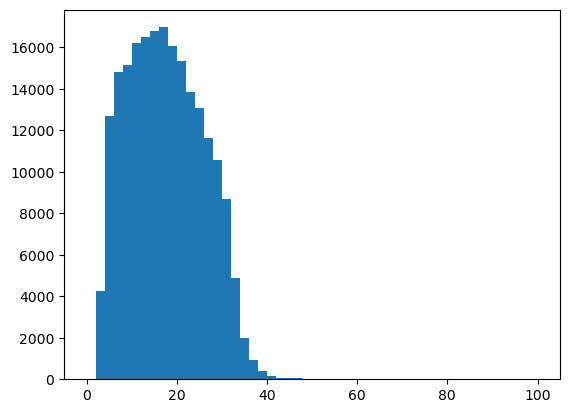

In [19]:
plt.hist(length_e, bins=50, range=(0,100))

In [20]:
total_labels_count = y_main.sum(axis=0)
total_labels_count

admiration        17131
amusement          9245
anger              8084
annoyance         13618
approval          17620
caring             5999
confusion          7359
curiosity          9692
desire             3817
disappointment     8469
disapproval       11424
disgust            5301
embarrassment      2476
excitement         5629
fear               3197
gratitude         11625
grief               673
joy                7983
love               8191
nervousness        1810
optimism           8715
pride              1302
realization        8785
relief             1289
remorse            2525
sadness            6758
surprise           5514
neutral           55298
dtype: int64

(array([0.08110309, 0.04376849, 0.03827198, 0.06447154, 0.08341816,
        0.02840099, 0.03483963, 0.04588472, 0.01807078, 0.04009469,
        0.05408451, 0.02509646, 0.0117221 , 0.02664931, 0.01513552,
        0.0550361 , 0.00318618, 0.03779382, 0.03877855, 0.00856906,
        0.04125932, 0.00616404, 0.04159072, 0.0061025 , 0.01195408,
        0.03199432, 0.02610486, 0.26179666]),
 array([ 0.        ,  0.96428571,  1.92857143,  2.89285714,  3.85714286,
         4.82142857,  5.78571429,  6.75      ,  7.71428571,  8.67857143,
         9.64285714, 10.60714286, 11.57142857, 12.53571429, 13.5       ,
        14.46428571, 15.42857143, 16.39285714, 17.35714286, 18.32142857,
        19.28571429, 20.25      , 21.21428571, 22.17857143, 23.14285714,
        24.10714286, 25.07142857, 26.03571429, 27.        ]),
 <BarContainer object of 28 artists>)

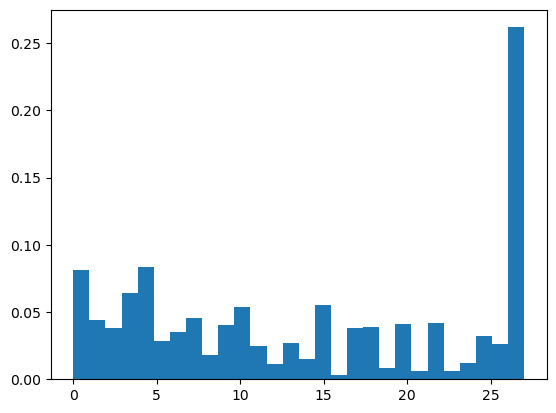

In [21]:
plt.hist(range(total_labels_count.shape[-1]), bins=28, weights=total_labels_count / len(X_main))

In [22]:
label_weights = total_labels_count.max() / total_labels_count
label_weights

admiration         3.227949
amusement          5.981395
anger              6.840426
annoyance          4.060655
approval           3.138365
caring             9.217870
confusion          7.514336
curiosity          5.705530
desire            14.487294
disappointment     6.529460
disapproval        4.840511
disgust           10.431617
embarrassment     22.333603
excitement         9.823770
fear              17.296841
gratitude          4.756817
grief             82.166419
joy                6.926970
love               6.751068
nervousness       30.551381
optimism           6.345152
pride             42.471582
realization        6.294593
relief            42.899922
remorse           21.900198
sadness            8.182598
surprise          10.028654
neutral            1.000000
dtype: float64

In [23]:
class_weights = dict(enumerate(label_weights))
class_weights

{0: 3.227949331621038,
 1: 5.981395348837209,
 2: 6.840425531914893,
 3: 4.060655015420767,
 4: 3.138365493757094,
 5: 9.217869644940823,
 6: 7.514336186981927,
 7: 5.705530334296327,
 8: 14.487293686140948,
 9: 6.529460384933286,
 10: 4.840511204481793,
 11: 10.43161667609885,
 12: 22.333602584814216,
 13: 9.823769763723574,
 14: 17.296840788238974,
 15: 4.7568172043010755,
 16: 82.16641901931649,
 17: 6.926969810848052,
 18: 6.751068245635453,
 19: 30.551381215469615,
 20: 6.345152036718302,
 21: 42.4715821812596,
 22: 6.294593056346044,
 23: 42.89992242048099,
 24: 21.90019801980198,
 25: 8.182598401894051,
 26: 10.028654334421473,
 27: 1.0}

In [24]:
class Dataset(keras.utils.PyDataset):

    def __init__(
            self,
            X: list[list[int]],
            y: list[list[int]],
            batch_size: int,
            fixed_length: int | None = None,
            seed: int | None = None, 
            shuffle: bool = False, 
            **kwargs
    ):
        super().__init__(**kwargs)
        self.shuffle = shuffle
        self.batch_size = batch_size
        self.seed = seed
        self.rng = np.random.default_rng(seed)

        self.X = X
        self.y = np.array(y)

        self.fixed_length = fixed_length if fixed_length else None

        self.image_index = np.arange(len(self.X))

        self.on_epoch_end()

    def __len__(self):
        return (len(self.X) + self.batch_size - 1) // self.batch_size

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.image_index)
    
    def __getitem__(self, index: int):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        batch = self.image_index[start:end]

        _X = [self.X[idx] for idx in batch]

        batch_lenth = self.fixed_length

        if batch_lenth is None:
            batch_lenth = int(np.quantile([len(seq) for seq in _X], 0.8))
            add_noise = self.rng.integers(-batch_lenth // 2, batch_lenth // 2, endpoint=True)
            batch_lenth += add_noise

        _X = keras.utils.pad_sequences(_X, maxlen=batch_lenth, padding='post', truncating='post', value=tokenizer.eos_token_id)

        return _X, self.y[batch]


In [25]:
gss = sklearn.model_selection.GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df_dataset, groups=df_dataset["text"]))

In [26]:
X_train_main, X_test_main = [X_main[i] for i in train_idx], [X_main[i] for i in test_idx]
y_train_main, y_test_main = y_main.loc[train_idx], y_main.loc[test_idx]

In [27]:
BATCH_SIZE = 1024

In [28]:
train_fixed = Dataset(X_train_main, y_train_main, batch_size=BATCH_SIZE, fixed_length=32, seed=42, shuffle=True)
test_fixed =  Dataset(X_test_main, y_test_main, batch_size=BATCH_SIZE, fixed_length=32, seed=42, shuffle=False)

In [29]:
train_variable = Dataset(X_train_main, y_train_main, batch_size=BATCH_SIZE, fixed_length=None, seed=42, shuffle=True)
test_variable = Dataset(X_test_main, y_test_main, batch_size=BATCH_SIZE, fixed_length=None, seed=42, shuffle=False)

In [91]:
for i in range(10):
    print(test_variable[i][0].shape)

(1024, 16)
(1024, 36)
(1024, 34)
(1024, 28)
(1024, 22)
(1024, 33)
(1024, 27)
(1024, 23)
(1024, 25)
(1024, 17)


# Model

Implement your model. The model should have the RNN architecture (with LSTM or GRU cells), support stacking and bidirectional feature extraction.

In [30]:
def get_name(prefix: str | None = None, suffix: str | None = None, separator: str = '_') -> str | None:
    return prefix and prefix + separator + suffix or suffix or None

In [31]:
def get_model(
    units: int,
    n_tokens: int,
    n_labels: int,
    n_stacks: int = 1,
    bidirectional: bool = False,
    name: str | None = None,
    # cell_type: type[keras.layers.Layer] = keras.layers.LSTMCell,
    cell_type: type[keras.layers.LSTMCell] | type[keras.layers.GRUCell] = keras.layers.LSTMCell,
) -> keras.Model:
    '''Creates a model with RNN architecture for sequence multilabel classification.

    Arguments:
        units: dimensionality of RNN cells
        n_tokens: number of tokens in the tokenizer dictionary
        n_labels: number of labels to be predicted
        n_stacks: number of RNN cells in the stack (1 -- no stacking)
        bidirectional: whether or not the model is bidirectional
        name: the model name
        cell_type: type of a cell to use, either keras.layers.LSTMCell or keras.layers.GRUCell

    Returns:
        The model'''

    inputs = x = keras.layers.Input((None,), dtype='int32', name='input')
    x = keras.layers.Embedding(n_tokens, units, name='embedding')(x)

    cells = [cell_type(units) for _ in range(n_stacks)]
    stacked_cells = keras.layers.StackedRNNCells(cells)
    rnn = keras.layers.RNN(
        stacked_cells,
        return_sequences=False,
        name="rnn_cell",
    )

    if bidirectional:
        rnn = keras.layers.Bidirectional(rnn, name=f"bidirectional")

    x = rnn(x)

    x = keras.layers.Dropout(0.2, name="dropout")(x)
    x = keras.layers.Dense(n_labels, activation='sigmoid', name='output')(x)
    return keras.models.Model(
        inputs=inputs, 
        outputs=x, 
        name=name
    )

In [95]:
# model_test = get_model(
#         units=32,
#         n_tokens=len(tokenizer.get_vocab()),
#         n_labels=len(emotions),
#         name="TEST",
#         bidirectional=False,
#         n_stacks=1,
#         cell_type=keras.layers.LSTMCell
#     )

# model_test.summary()

# Training

Train several models on the two dataset variants. Use either of the cell types (LSTM or GRU)
* Simple RNN (no stacking, one direction)
* Stacked RNN (stacking, one direction)
* Bidirectional RNN (no stacking, bidirectional)
* Stacked Bidirectional RNN (stacking, bidirectional)

In [32]:
ModelConfig = collections.namedtuple("ModelConfig", ["fixed", "units", "bidirectional", "stacks", "cell_type"])

In [33]:
model_configs = [
    ModelConfig(*c) 
    for c in itertools.product(
        [True, False],
        [128],
        [False, True],
        [1, 2],
        [keras.layers.LSTMCell],
    )
]
model_configs

[ModelConfig(fixed=True, units=128, bidirectional=False, stacks=1, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=True, units=128, bidirectional=False, stacks=2, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=True, units=128, bidirectional=True, stacks=1, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=True, units=128, bidirectional=True, stacks=2, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=False, units=128, bidirectional=False, stacks=1, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=False, units=128, bidirectional=False, stacks=2, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=False, units=128, bidirectional=True, stacks=1, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=False, units=128, bidirectional=True, stacks=2, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>)]

In [34]:
def get_model_name(config: ModelConfig):
    return f"{config.cell_type.__name__}-{config.units} x {config.stacks} {'B ' if config.bidirectional else ''}{'F' if config.fixed else 'V'}"

In [99]:
models = [
    get_model(
        units=config.units,
        n_tokens=len(tokenizer.get_vocab()),
        n_labels=len(emotions),
        name=get_model_name(config),
        bidirectional=config.bidirectional,
        n_stacks=config.stacks,
        cell_type=config.cell_type
    )
    for config in model_configs
]

2026-10-16 20:50:24.786613: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [100]:
models

[<Functional name=LSTMCell-128 x 1 F, built=True>,
 <Functional name=LSTMCell-128 x 2 F, built=True>,
 <Functional name=LSTMCell-128 x 1 B F, built=True>,
 <Functional name=LSTMCell-128 x 2 B F, built=True>,
 <Functional name=LSTMCell-128 x 1 V, built=True>,
 <Functional name=LSTMCell-128 x 2 V, built=True>,
 <Functional name=LSTMCell-128 x 1 B V, built=True>,
 <Functional name=LSTMCell-128 x 2 B V, built=True>]

In [101]:
models[7].summary()

Model: "LSTMCell-128 x 2 B V"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 128)      │     6,432,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │       526,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 28)             │         7,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,966,428 (26.57 MB)

 Trainable params: 6,966,428 (26.57 MB)

 Non-trainable params: 0 (0.00 B)

Which loss should be used to multilabel classification? Which metrics?

In [35]:
SAVE_MODEL_PATH = Path("./saved")

In [103]:
for model in models:
    model.compile(
        loss=keras.losses.BinaryCrossentropy(from_logits=False),
        optimizer=keras.optimizers.Adam(),
        metrics=[
            keras.metrics.BinaryAccuracy(),
            keras.metrics.AUC(multi_label=True, num_labels=len(emotions)),
            keras.metrics.F1Score(average="macro"),
        ]
    )

In [104]:
for model in models[:4]:
    print()
    print(model.name)
    
    model.fit(
        train_fixed,
        validation_data=test_fixed,
        epochs=10,
        callbacks=[
            keras.callbacks.ModelCheckpoint(
                SAVE_MODEL_PATH / f"{model.name}.keras"
            )
        ],
        class_weight=class_weights
    )


LSTMCell-128 x 1 F
Epoch 1/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 17s 101ms/step - auc: 0.4992 - binary_accuracy: 0.9513 - f1_score: 0.0333 - loss: 1.1837 - val_auc: 0.5013 - val_binary_accuracy: 0.9577 - val_f1_score: 0.0021 - val_loss: 0.1730
Epoch 2/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - auc: 0.5002 - binary_accuracy: 0.9578 - f1_score: 0.0340 - loss: 1.0087 - val_auc: 0.5010 - val_binary_accuracy: 0.9577 - val_f1_score: 0.0021 - val_loss: 0.1730
Epoch 3/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 16s 99ms/step - auc: 0.4994 - binary_accuracy: 0.9578 - f1_score: 0.0338 - loss: 1.0051 - val_auc: 0.5009 - val_binary_accuracy: 0.9577 - val_f1_score: 0.0069 - val_loss: 0.1727
Epoch 4/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - auc: 0.5010 - binary_accuracy: 0.9578 - f1_score: 0.0330 - loss: 1.0026 - val_auc: 0.5006 - val_binary_accuracy: 0.9577 - val_f1_score: 0.0021 - val_loss: 0.1726
Epoch 5/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 17s 106ms/step - auc: 0.5009 - binary_accuracy: 0.9578 - f1_score

In [110]:
for model in models[4:]:
    print()
    print(model.name)
    
    model.fit(
        train_variable,
        validation_data=test_variable,
        epochs=10,
        callbacks=[
            keras.callbacks.ModelCheckpoint(
                SAVE_MODEL_PATH / f"{model.name}.keras"
            )
        ],
        class_weight=class_weights
    )


LSTMCell-128 x 1 V
Epoch 1/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 16s 96ms/step - auc_4: 0.7603 - binary_accuracy: 0.9589 - f1_score: 0.1503 - loss: 0.8495 - val_auc_4: 0.7414 - val_binary_accuracy: 0.9590 - val_f1_score: 0.1505 - val_loss: 0.1501
Epoch 2/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 15s 89ms/step - auc_4: 0.7935 - binary_accuracy: 0.9592 - f1_score: 0.1965 - loss: 0.8017 - val_auc_4: 0.7579 - val_binary_accuracy: 0.9592 - val_f1_score: 0.1928 - val_loss: 0.1470
Epoch 3/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 15s 93ms/step - auc_4: 0.8168 - binary_accuracy: 0.9593 - f1_score: 0.2376 - loss: 0.7600 - val_auc_4: 0.7658 - val_binary_accuracy: 0.9588 - val_f1_score: 0.2022 - val_loss: 0.1458
Epoch 4/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 15s 89ms/step - auc_4: 0.8329 - binary_accuracy: 0.9592 - f1_score: 0.2719 - loss: 0.7283 - val_auc_4: 0.7652 - val_binary_accuracy: 0.9589 - val_f1_score: 0.2208 - val_loss: 0.1461
Epoch 5/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 14s 87ms/step - auc_4: 0.8437 - binary_accuracy: 0.9

In [36]:
models = [
    keras.models.load_model(
        SAVE_MODEL_PATH / f"{get_model_name(config)}.keras"
    )
    for config in model_configs
]
models

2026-10-19 18:35:19.799953: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


[<Functional name=LSTMCell-128 x 1 F, built=True>,
 <Functional name=LSTMCell-128 x 2 F, built=True>,
 <Functional name=LSTMCell-128 x 1 B F, built=True>,
 <Functional name=LSTMCell-128 x 2 B F, built=True>,
 <Functional name=LSTMCell-128 x 1 V, built=True>,
 <Functional name=LSTMCell-128 x 2 V, built=True>,
 <Functional name=LSTMCell-128 x 1 B V, built=True>,
 <Functional name=LSTMCell-128 x 2 B V, built=True>]

# Evaluation

Evaluate the models you trained on the test datasets. Plot ROC curves for each label (use `sklearn.metrics.RocCurveDisplay`) for each model.

In [37]:
def plot_roc_curve(
    X: np.ndarray,
    y: np.ndarray,
    model: keras.Model,
    ax: plt.Axes | None = None,
    is_legend: bool = False,
    batch_size: int = BATCH_SIZE,
) -> float:
    '''Plots ROC curves for each of the labels (on a single axes) and outputs mean ROC AUC score.

    Arguments:
        X: model inputs
        y: ground thruths
        model: model to plot the curve for
        ax: axes to plot on

    Returns:
        Mean ROC AUC score'''

    if ax is None:
        ax = plt.gca()

    y_pred = model.predict(X, batch_size=batch_size)

    # aucs = []
    for i in range(y.shape[-1]):
        disp = sklearn.metrics.RocCurveDisplay.from_predictions(
            y[:, i], 
            y_pred[:, i], 
            name=f"Class {i}",
            ax=ax
        )
        # aucs.append(disp.roc_auc)

    ax.plot([0, 1], [0, 1], "k--")
    ax.grid(True)
    # mean_auc = np.mean(aucs)
    mean_auc = sklearn.metrics.roc_auc_score(y, y_pred)

    if not is_legend:
        ax.get_legend().remove()

    ax.set_title(f"ROC AUC: {mean_auc:.3f}")

    return mean_auc

42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step


0.7502512375726649

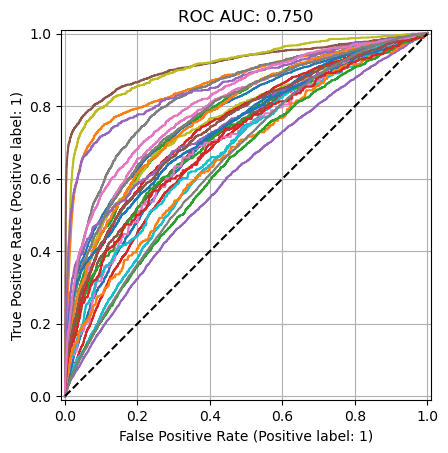

In [123]:
plot_roc_curve(test_variable, test_fixed.y, models[7])

Plot the mean ROC AUC scores. Which model has the highest score? On what kind of dataset?

42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 9s 203ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 8s 199ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 117ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 8s 180ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 6s 140ms/step


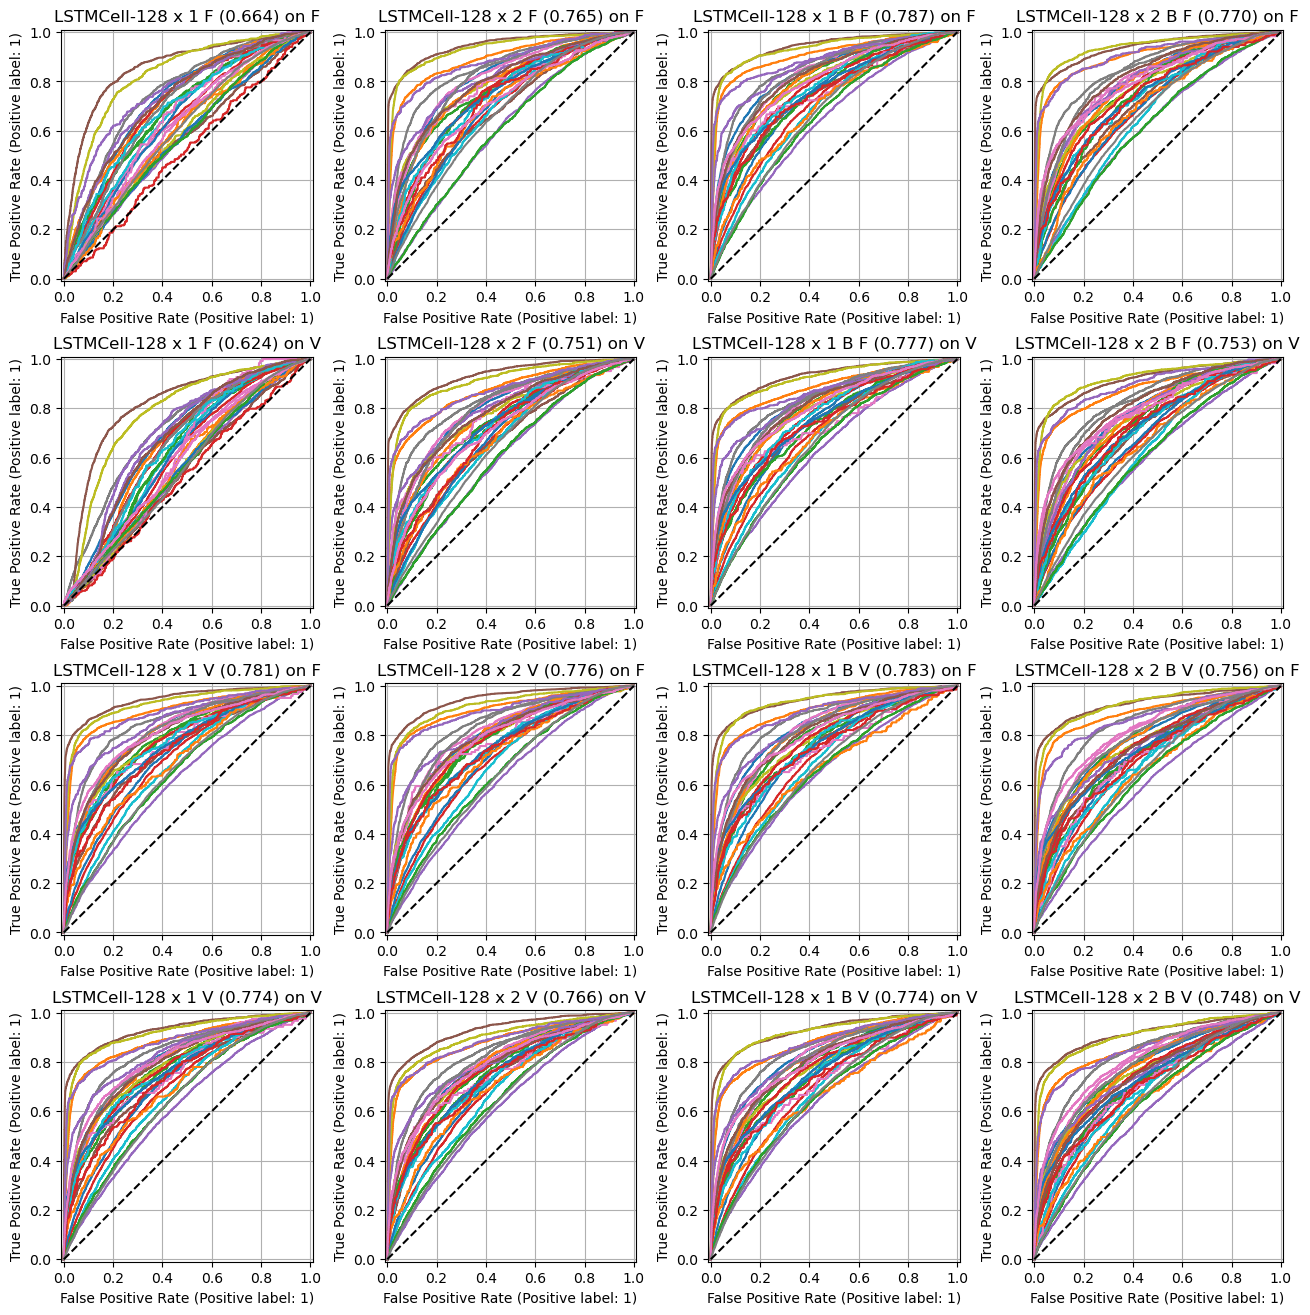

In [112]:
fig, axs = plt.subplots(4, 4, figsize=(16, 16))

for i, model in enumerate(models):
    row = i // 4
    col = i % 4
    ax1 = axs[2 * row, col]
    roc_auc = plot_roc_curve(test_fixed, test_fixed.y, model, ax=ax1)
    ax1.set_title(f"{model.name} ({roc_auc:.3f}) on F")
    
    ax2 = axs[2 * row + 1, col]
    roc_auc = plot_roc_curve(test_variable, test_variable.y, model, ax=ax2)
    ax2.set_title(f"{model.name} ({roc_auc:.3f}) on V")

plt.subplots_adjust(hspace=0.3)

Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [38]:
def label_text(text: str, model: keras.Model, threshold: float = 0.5, max_length: int | None = None) -> list[str]:
    '''Computes the model output for `text` and outputs a list of emotions that have a probability of at least `threshold`

    Arguments:
        text: text to label
        model: model to use
        threshold: threshold to use
        max_length: max length for tokenization
    
    Return:
        List of predicted emotion labels'''

    tokens = np.array([tokenizer.encode(text, max_length=max_length)])
    y_pred = model.predict(tokens, verbose=0)[0] > threshold
    return [e for e, y in zip(emotions, y_pred) if y]

In [39]:
def plot_emotion_scores(text: str, model: keras.Model, max_length: int | None = None, ax: plt.Axes | None = None):
    '''Plots a bar plot of emotion probabilities for given `text` using `model`.

    Arguments:
        text: text to label
        model: model to use        
        max_length: max length for tokenization
        ax: axes to plot on'''

    if ax is None:
        ax = plt.gca()

    tokens = np.array([tokenizer.encode(text, max_length=max_length)])
    y_pred = model.predict(tokens, verbose=0)[0]

    ax.bar(emotions, y_pred)
    ax.set_xticks(range(len(emotions)))
    ax.set_xticklabels(emotions, rotation=90)
    ax.grid(True)

For each of your texts get a list of emotion labels and plot emotion scores

In [48]:
some_texts = [
    "aahsdljhlj lj kjhlkahs",
    "Aasdkljf? uoifupoiur! 09090--!!",
    "ылдважопждлывоалдожш мымшоуы шош",
    
    "23094!(*$809-434=-0_",
    'empty',
    'emtpyness',
    
    "I just came up with simple yet exciting solution to this question",
    "I just came up with simple yet exciting solution to this question!",
    "I just came up with simple yet exciting solution to this question?",
    
    'I want to get this chocolate',
    "How are you doing here?",
    "I hate that nothing is working out",
    
    "Spiders are scary for those with arachnafobia",
    "yo dudes! this chad is sigma!!! 67",
    "You can watch some tutorials on YouTube",
    
    "Greetings, my dear King!",
    "Greetings, my friend!",
    "Greetings, my lovely lady!",
    
    'Have you seen John in the last five or so days?',
    'Have you seen John in the last five or so days? I am worried about him',
    'Have you seen John in the last five or so days? He should\'ve finished with that damn project already!',
    
    "wow, this is so uninteresting...",
    "this is so uninteresting...",
    "THIS IS SOOOO UNINTERESTINGGG!!!",

    "This is a neutral sentence",
    "OH MY GOD!",
    # 'The quick brown fox jumps over the lazy dog',

    "James while John had had had had had had had had had had had a better effect on the teacher",
]

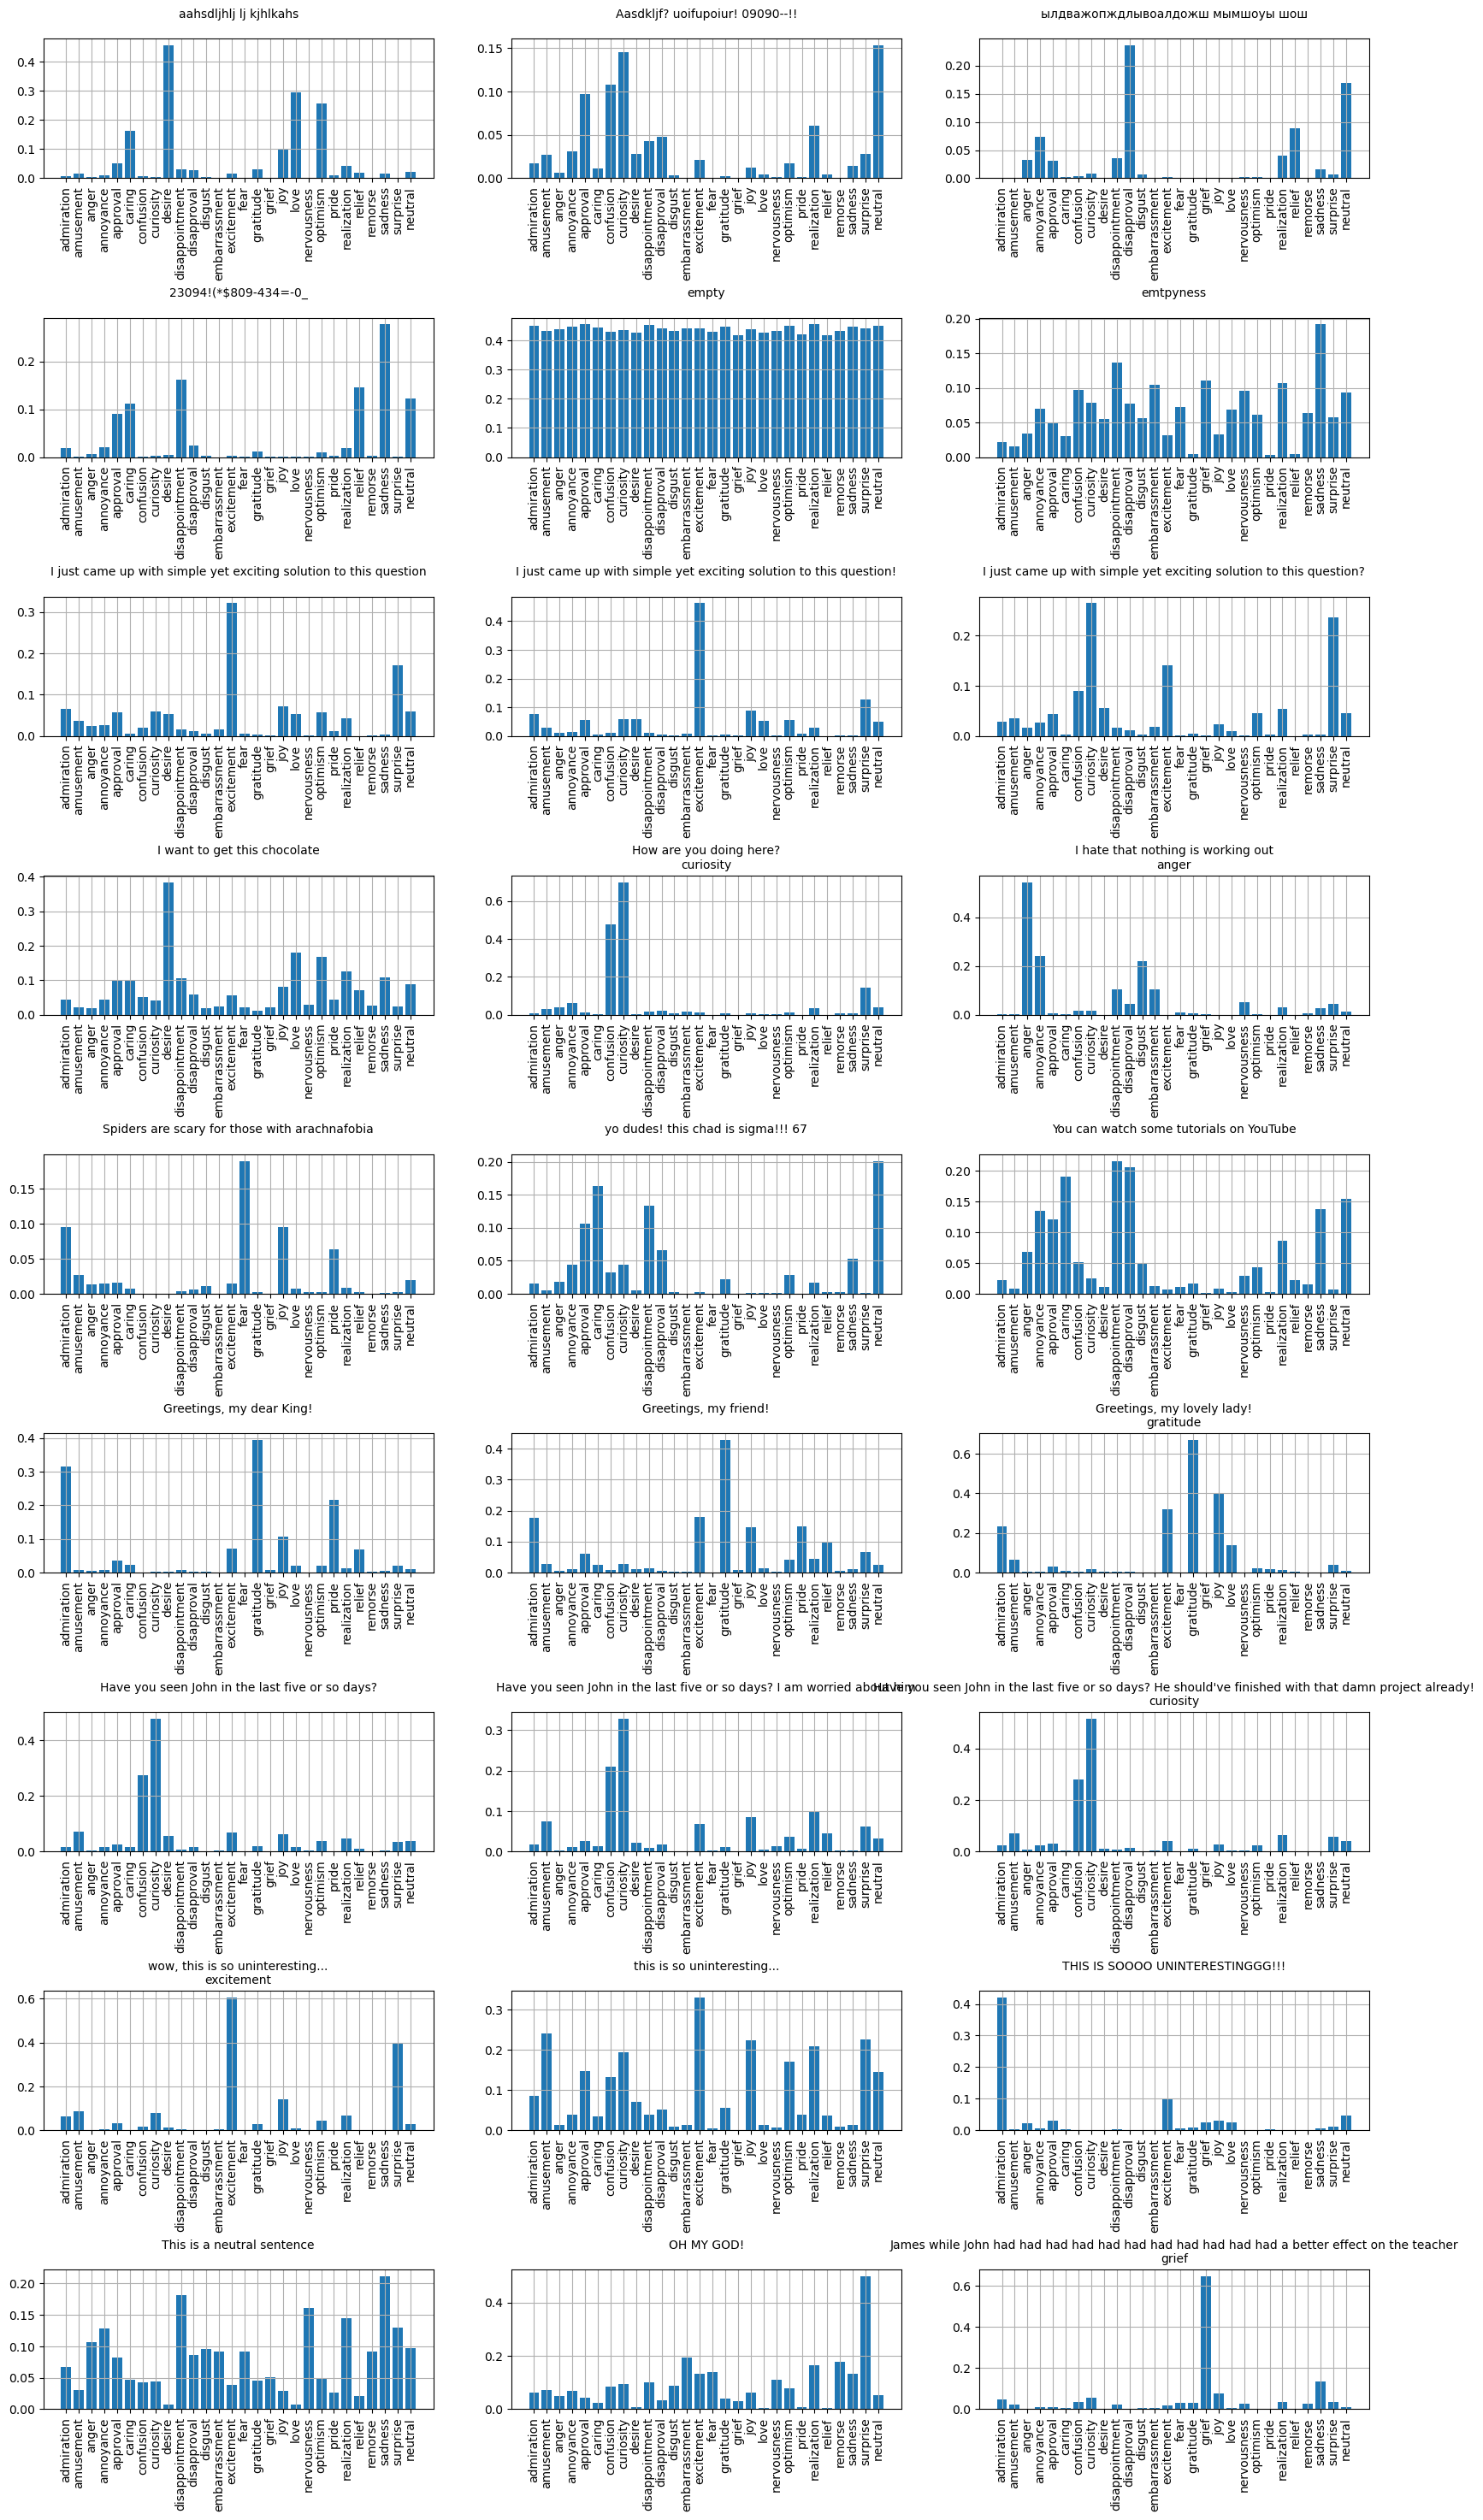

In [49]:
rows, cols = 9, 3

t_fig, t_axs = plt.subplots(rows, cols, figsize=(20, rows * 4))

selected_model = models[7]

for i, t in enumerate(some_texts):
    row = i // cols
    col = i % cols

    labels = label_text(t, selected_model)

    ax = t_axs[row, col]
    plot_emotion_scores(t, selected_model, ax=ax)
    ax.set_title(f"{t}\n{', '.join(labels)}", fontsize=10)
    
plt.subplots_adjust(hspace=1)

# Bonus

Train and evaluate the same model as your best one, but use a different cell type

In [44]:
model_configs2 = [
    ModelConfig(*c) 
    for c in itertools.product(
        [False],
        [128],
        [False, True],
        [2],
        [keras.layers.GRUCell],
    )
]
model_configs2

[ModelConfig(fixed=False, units=128, bidirectional=False, stacks=2, cell_type=<class 'keras.src.layers.rnn.gru.GRUCell'>),
 ModelConfig(fixed=False, units=128, bidirectional=True, stacks=2, cell_type=<class 'keras.src.layers.rnn.gru.GRUCell'>)]

In [45]:
models2 = [
    get_model(
        units=config.units,
        n_tokens=len(tokenizer.get_vocab()),
        n_labels=len(emotions),
        name=get_model_name(config),
        bidirectional=config.bidirectional,
        n_stacks=config.stacks,
        cell_type=config.cell_type
    )
    for config in model_configs2
]
models2

[<Functional name=GRUCell-128 x 2 V, built=True>,
 <Functional name=GRUCell-128 x 2 B V, built=True>]

In [119]:
for model in models2:
    model.compile(
        loss=keras.losses.BinaryCrossentropy(from_logits=False),
        optimizer=keras.optimizers.Adam(),
        metrics=[
            keras.metrics.BinaryAccuracy(),
            keras.metrics.AUC(multi_label=True, num_labels=len(emotions)),
            keras.metrics.F1Score(average="macro"),
        ]
    )

In [120]:
for model in models2:
    print()
    print(model.name)
    
    model.fit(
        train_variable,
        validation_data=test_variable,
        epochs=10,
        callbacks=[
            keras.callbacks.ModelCheckpoint(
                SAVE_MODEL_PATH / f"{model.name}.keras"
            )
        ],
        class_weight=class_weights
    )


GRUCell-128 x 2 V
Epoch 1/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 28s 167ms/step - auc_8: 0.4995 - binary_accuracy: 0.9508 - f1_score: 0.0340 - loss: 1.2152 - val_auc_8: 0.5004 - val_binary_accuracy: 0.9577 - val_f1_score: 0.0044 - val_loss: 0.1726
Epoch 2/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 29s 173ms/step - auc_8: 0.5024 - binary_accuracy: 0.9578 - f1_score: 0.0363 - loss: 1.0279 - val_auc_8: 0.5429 - val_binary_accuracy: 0.9577 - val_f1_score: 0.0237 - val_loss: 0.1708
Epoch 3/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 28s 172ms/step - auc_8: 0.5566 - binary_accuracy: 0.9585 - f1_score: 0.0667 - loss: 0.9899 - val_auc_8: 0.6468 - val_binary_accuracy: 0.9587 - val_f1_score: 0.0951 - val_loss: 0.1606
Epoch 4/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 28s 172ms/step - auc_8: 0.6747 - binary_accuracy: 0.9591 - f1_score: 0.1319 - loss: 0.9139 - val_auc_8: 0.7108 - val_binary_accuracy: 0.9592 - val_f1_score: 0.1563 - val_loss: 0.1539
Epoch 5/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 27s 164ms/step - auc_8: 0.7503 - binary_accuracy:

In [46]:
models2 = [
    keras.models.load_model(
        SAVE_MODEL_PATH / f"{get_model_name(config)}.keras"
    )
    for config in model_configs2
]
models2

[<Functional name=GRUCell-128 x 2 V, built=True>,
 <Functional name=GRUCell-128 x 2 B V, built=True>]

42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 6s 135ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step


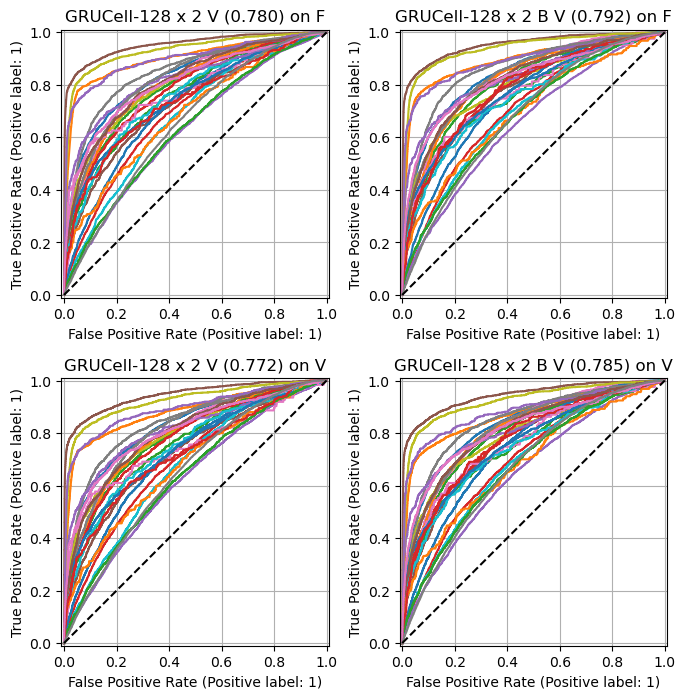

In [121]:
fig, axs = plt.subplots(2, 2, figsize=(8, 8))

for i, model in enumerate(models2):
    row = i // 4
    col = i % 4
    ax1 = axs[2 * row, col]
    roc_auc = plot_roc_curve(test_fixed, test_fixed.y, model, ax=ax1)
    ax1.set_title(f"{model.name} ({roc_auc:.3f}) on F")
    
    ax2 = axs[2 * row + 1, col]
    roc_auc = plot_roc_curve(test_variable, test_variable.y, model, ax=ax2)
    ax2.set_title(f"{model.name} ({roc_auc:.3f}) on V")

plt.subplots_adjust(hspace=0.3)

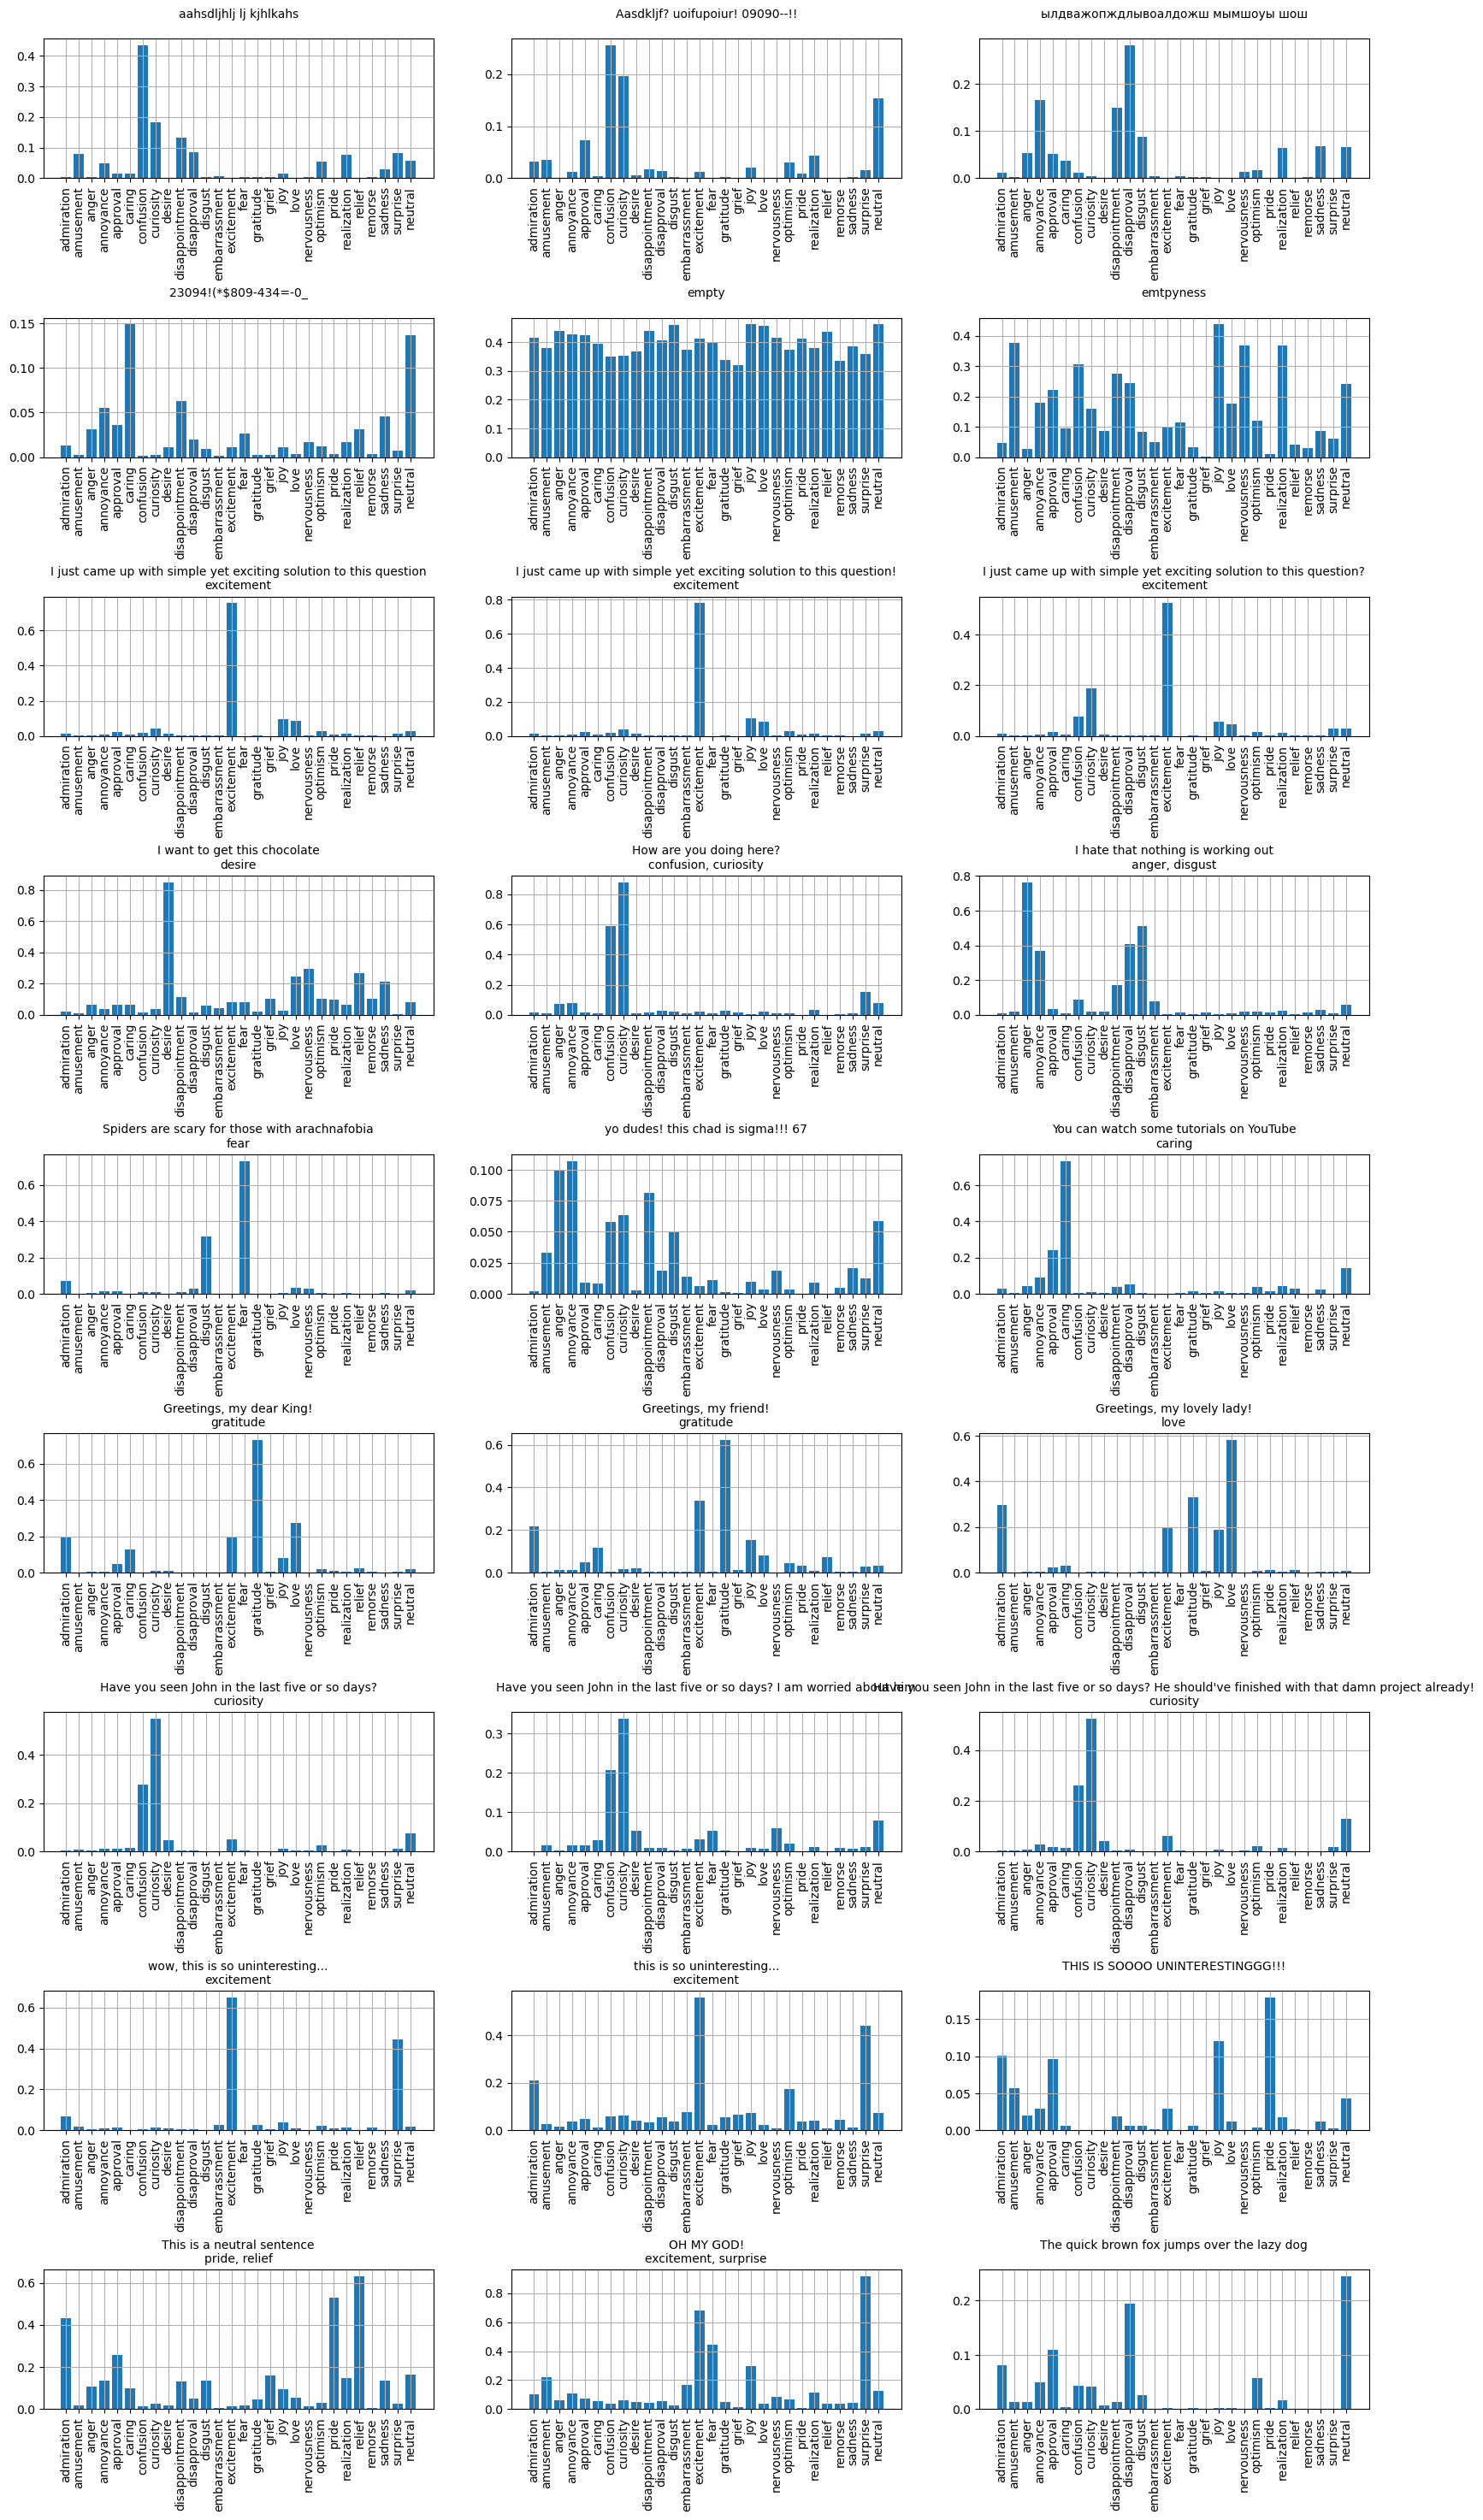

In [47]:
rows, cols = 9, 3

t_fig, t_axs = plt.subplots(rows, cols, figsize=(20, rows * 4))

selected_model = models2[1]

for i, t in enumerate(some_texts):
    row = i // cols
    col = i % cols

    labels = label_text(t, selected_model)

    ax = t_axs[row, col]
    plot_emotion_scores(t, selected_model, ax=ax)
    ax.set_title(f"{t}\n{', '.join(labels)}", fontsize=10)
    
plt.subplots_adjust(hspace=1)